# Assignment 02 - Fitting and Alignment

Index Number: 230525U

## Q.1

Image dimensions: (360, 360, 3)


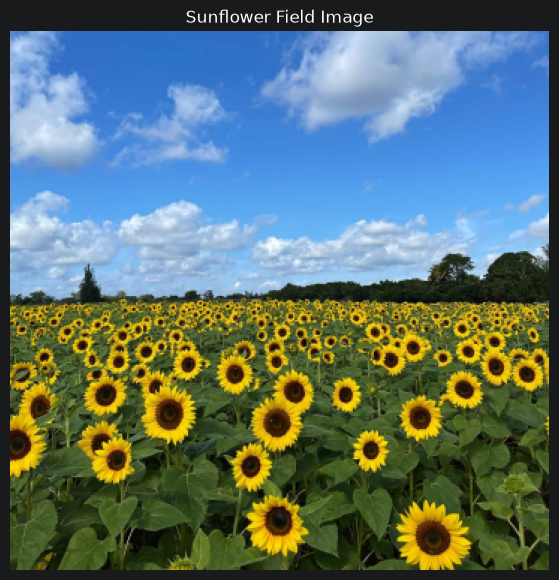

In [20]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the sunflower field image
image_path = Path("images/the_berry_farms_sunflower_field.jpeg")

im = cv.imread(str(image_path), cv.IMREAD_REDUCED_COLOR_4)

if im is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

# Convert BGR to RGB for visualization
im_rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)

print(f"Image dimensions: {im.shape}")

plt.figure(figsize=(12, 7))
plt.imshow(im_rgb)
plt.title("Sunflower Field Image")
plt.axis("off")
plt.show()


Number of detected blobs: 57
Sigma range: 1.0 to 8.0


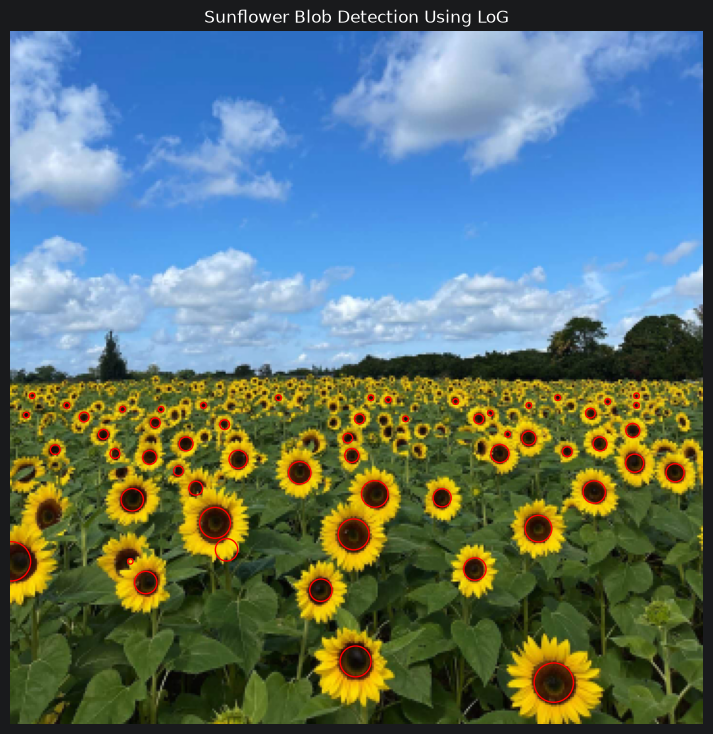

In [38]:

from scipy.ndimage import maximum_filter

# Parameters
scales = np.linspace(1, 8, 10)
response_threshold = 0.67

gray_image = cv.cvtColor(im, cv.COLOR_BGR2GRAY)

responses = []

# Construct scale-normalized LoG scale space
for sigma in scales:
    half_size = round(3 * sigma)

    xx, yy = np.meshgrid(
        np.arange(-half_size, half_size + 1),
        np.arange(-half_size, half_size + 1)
    )

    d2 = xx**2 + yy**2

    log_kernel = (
        (d2 / (2 * sigma**2) - 1)
        * np.exp(-d2 / (2 * sigma**2))
        / (np.pi * sigma**4)
    )

    # Scale normalization
    log_kernel *= sigma**2

    response = cv.filter2D(
        gray_image, cv.CV_32F, log_kernel
    )**2

    responses.append(response)

# Shape: (height, width, number of scales)
scale_space = np.stack(responses, axis=-1)

# 3D non-maximum suppression
local_max = maximum_filter(
    scale_space, size=(3, 3, 3)
)

# Threshold relative to maximum at EACH scale
thresholds = (
    response_threshold
    * scale_space.max(axis=(0, 1), keepdims=True)
)

maxima = (
    (scale_space == local_max)
    & (scale_space >= thresholds)
)

# Extract detected blobs
rows, cols, scale_indices = np.where(maxima)

sigmas = scales[scale_indices]
radii = np.sqrt(2) * sigmas

print("Number of detected blobs:", len(rows))
print("Sigma range:", scales[0], "to", scales[-1])

# Visualization
fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(im_rgb)

for row, col, radius in zip(rows, cols, radii):
    circle = plt.Circle(
        (col, row), radius,
        edgecolor="red",
        fill=False,
        linewidth=1
    )
    ax.add_patch(circle)

ax.set_title("Sunflower Blob Detection Using LoG")
ax.axis("off")
plt.show()


In [39]:

# Report the 10 largest detected circles
largest_indices = np.argsort(radii)[::-1][:10]

print(f"Sigma range: {scales[0]:.2f} - {scales[-1]:.2f}")
print(f"Total detected blobs: {len(radii)}")
print()

print(f"{'Center X':<12}{'Center Y':<12}{'Radius':<12}{'Sigma':<12}")
print("-" * 48)

for i in largest_indices:
    print(
        f"{cols[i]:<12}"
        f"{rows[i]:<12}"
        f"{radii[i]:<12.2f}"
        f"{sigmas[i]:<12.2f}"
    )


Sigma range: 1.00 - 8.00
Total detected blobs: 57

Center X    Center Y    Radius      Sigma       
------------------------------------------------
282         338         10.21       7.22        
0           275         10.21       7.22        
179         327         8.01        5.67        
178         261         8.01        5.67        
106         255         8.01        5.67        
274         258         6.91        4.89        
189         240         6.91        4.89        
241         279         5.81        4.11        
161         290         5.81        4.11        
303         239         5.81        4.11        
